# Analysis: Childhood Lead Exposure and Violent Crime

Querying the DuckDB database to build one row per neighborhood with lead exposure, violent crime rate, and hardship index, then charting and testing the relationship.

In [78]:
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import pandas as pd

In [79]:
con = duckdb.connect("../data/lead_crime.duckdb", read_only=True)

## Check that types loaded correctly

'read_csv_auto' guesses column types, so confirming they match what 'transform.py' produced.

In [80]:
con.sql("DESCRIBE lead").show()

┌───────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│      column_name      │ column_type │  null   │   key   │ default │  extra  │
│        varchar        │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ community_area_number │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ year                  │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ percent_elevated      │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ kids_screened         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└───────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [81]:
con.sql("DESCRIBE crime").show()

┌─────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│       column_name       │ column_type │  null   │   key   │ default │  extra  │
│         varchar         │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ community_area_number   │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ year                    │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ violent_crime_incidents │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [82]:
con.sql("SELECT COUNT(*) FROM lead WHERE kids_screened IS NULL").show()

┌──────────────┐
│ count_star() │
│    int64     │
├──────────────┤
│           11 │
└──────────────┘



'year' is an integer in both tables, so they can join. Riverdale's 11 missing years came through as NULL.

## Lead exposure, 1999-2003

Average percent of tested kids with elevated lead, per neighborhood. 'AVG()' skips NULLs, so Riverdale is averaged over its 4 years with data.

In [83]:
con.sql("""
    SELECT         
        community_area_number,
        ROUND(AVG(percent_elevated), 2) AS lead_1999_2003,
        COUNT(percent_elevated) AS years_with_data
    FROM lead
    WHERE year BETWEEN 1999 AND 2003
    GROUP BY community_area_number
    ORDER BY lead_1999_2003 DESC
""").show()

┌───────────────────────┬────────────────┬─────────────────┐
│ community_area_number │ lead_1999_2003 │ years_with_data │
│         int64         │     double     │      int64      │
├───────────────────────┼────────────────┼─────────────────┤
│                    68 │          29.04 │               5 │
│                    37 │           27.3 │               5 │
│                    26 │          26.28 │               5 │
│                    67 │           25.9 │               5 │
│                    25 │          25.52 │               5 │
│                    27 │          24.44 │               5 │
│                    29 │          22.66 │               5 │
│                    69 │          18.58 │               5 │
│                    23 │          18.22 │               5 │
│                    42 │          18.12 │               5 │
│                     · │             ·  │               · │
│                     · │             ·  │               · │
│                     · 

Checking Riverdale specifically.

In [84]:
con.sql("""
    SELECT         
        community_area_number,
        ROUND(AVG(percent_elevated), 2) AS lead_1999_2003,
        COUNT(percent_elevated) AS years_with_data
    FROM lead
    WHERE year BETWEEN 1999 AND 2003 AND community_area_number = 54
    GROUP BY community_area_number
""").show()

┌───────────────────────┬────────────────┬─────────────────┐
│ community_area_number │ lead_1999_2003 │ years_with_data │
│         int64         │     double     │      int64      │
├───────────────────────┼────────────────┼─────────────────┤
│                    54 │           4.57 │               4 │
└───────────────────────┴────────────────┴─────────────────┘



Riverdale: 4.57% over 4 years. If the 2003 zero had been left in, the average would have been 3.66%.

## Violent Crime, 2019-2023

First by raw count, to show why rates are needed.

In [85]:
con.sql("""
    SELECT crime.community_area_number,
        total_population,
        SUM(violent_crime_incidents) AS total_violent_crimes
    FROM crime
    JOIN population ON crime.community_area_number = population.community_area_number
    WHERE year BETWEEN 2019 AND 2023
    GROUP BY crime.community_area_number, total_population
    ORDER BY total_violent_crimes DESC
""").show()

┌───────────────────────┬──────────────────┬──────────────────────┐
│ community_area_number │ total_population │ total_violent_crimes │
│         int64         │      int64       │        int128        │
├───────────────────────┼──────────────────┼──────────────────────┤
│                    25 │           100278 │                 9212 │
│                    43 │            46276 │                 5689 │
│                    29 │            30355 │                 5389 │
│                    69 │            29052 │                 4447 │
│                    23 │            55015 │                 4366 │
│                    67 │            25971 │                 4159 │
│                    71 │            46483 │                 4001 │
│                    28 │            65370 │                 3985 │
│                    68 │            21337 │                 3934 │
│                    44 │            31440 │                 3866 │
│                     · │              ·   │    

Austin (25) has the most violent crime, but it’s also the largest neighborhood, with over 100,000 residents. Converting to a rate per 1,000 residents per year.

In [86]:
con.sql("""
    SELECT crime.community_area_number,
        total_population,
        SUM(violent_crime_incidents) AS total_violent_crimes,
        ROUND(SUM(violent_crime_incidents) / 5.0 / total_population * 1000, 1) AS violent_crime_rate
    FROM crime
    JOIN population ON crime.community_area_number = population.community_area_number
    WHERE year BETWEEN 2019 AND 2023
    GROUP BY crime.community_area_number, total_population
    ORDER BY violent_crime_rate DESC
""").show()

┌───────────────────────┬──────────────────┬──────────────────────┬────────────────────┐
│ community_area_number │ total_population │ total_violent_crimes │ violent_crime_rate │
│         int64         │      int64       │        int128        │       double       │
├───────────────────────┼──────────────────┼──────────────────────┼────────────────────┤
│                    37 │             2186 │                  557 │               51.0 │
│                    26 │            16345 │                 3662 │               44.8 │
│                    68 │            21337 │                 3934 │               36.9 │
│                    29 │            30355 │                 5389 │               35.5 │
│                    67 │            25971 │                 4159 │               32.0 │
│                    69 │            29052 │                 4447 │               30.6 │
│                    27 │            19855 │                 2877 │               29.0 │
│                    

By rate, Austin drops out of the top 5. Englewood's rate (36.9) is about double Austin's (18.4), even though Austin has more than twice as many total crimes.

Fuller Park has the highest rate (51.0), but only 2,186 residents, so its rate is the least stable.

## Combined neighborhood table

Lead exposure, violent crime rate, and hardship index in one row per neighborhood. The query is saved in 'sql/01_neighborhood_summary.sql'.

In [87]:
query = open("../sql/01_neighborhood_summary.sql").read()
summary = con.sql(query).df()
summary.shape

(77, 5)

In [88]:
summary.head()

,community_area_number,community_area_name,lead_1999_2003,violent_crime_rate,hardship_index
0,37,Fuller Park,27.30,51.0,97.0
1,26,West Garfield Park,26.28,44.8,92.0
2,68,Englewood,29.04,36.9,94.0
3,29,North Lawndale,22.66,35.5,87.0
4,67,West Englewood,25.90,32.0,89.0


Four of the top five neighborhoods for violent crime are also in the top five for lead exposure. The same neighborhoods also have the highest hardship scores (83-97), so poverty could explain both.

## Lead vs. violent crime

In [89]:
Path("../figures").mkdir(exist_ok=True)

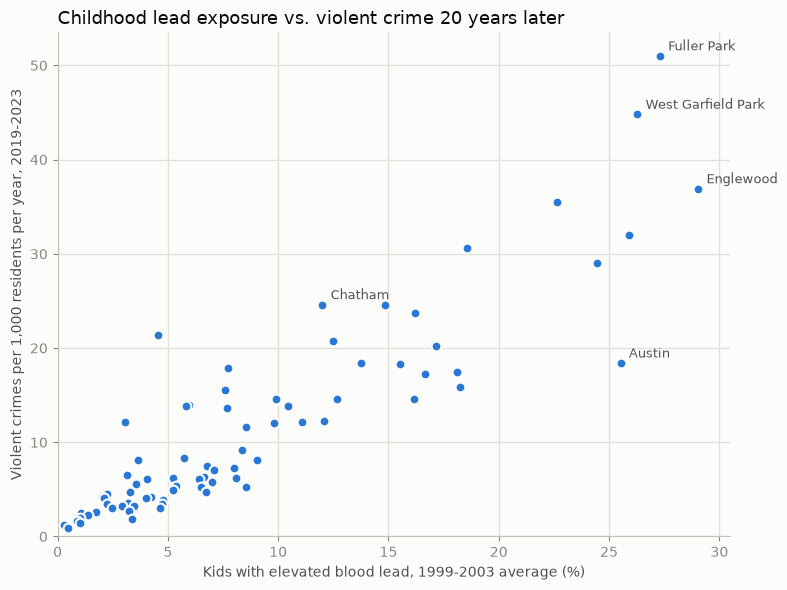

In [90]:
fig, ax = plt.subplots(figsize=(8, 6))

# One dot per neighborhood
ax.scatter(
    summary["lead_1999_2003"],
    summary["violent_crime_rate"],
    s=50,
    color="#2a78d6",
    edgecolor="#fcfcfb",
    linewidth=1.5,
    zorder=3,
)

# Label a few neighborhoods worth pointing out
to_label = ["Fuller Park", "West Garfield Park", "Englewood", "Chatham", "Austin"]
for _, row in summary[summary["community_area_name"].isin(to_label)].iterrows():
    ax.annotate(
        row["community_area_name"],
        (row["lead_1999_2003"], row["violent_crime_rate"]),
        xytext=(6, 4),
        textcoords="offset points",
        fontsize=9,
        color="#52514e",
    )

# Titles and axis labels
ax.set_title("Childhood lead exposure vs. violent crime 20 years later", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Kids with elevated blood lead, 1999-2003 average (%)", color="#52514e")
ax.set_ylabel("Violent crimes per 1,000 residents per year, 2019-2023", color="#52514e")

# Quiet background styling
ax.set_facecolor("#fcfcfb")
fig.set_facecolor("#fcfcfb")
ax.grid(color="#e1e0d9", linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
for side in ["left", "bottom"]:
    ax.spines[side].set_color("#c3c2b7")
ax.tick_params(colors="#898781")
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

fig.tight_layout()
fig.savefig("../figures/lead_vs_crime.png", dpi=200)
plt.show()

Neighborhoods with higher childhood lead exposure have higher violent crime rates 20 years later. The relationship is tight at low exposure levels and more spread out at high levels.

### The main exception

One neighborhood has high violent crime despite low lead exposure.

In [91]:
summary[(summary["lead_1999_2003"] < 6) & (summary["violent_crime_rate"] > 18)]

,community_area_number,community_area_name,lead_1999_2003,violent_crime_rate,hardship_index
10,54,Riverdale,4.57,21.4,98.0


Riverdale: low lead exposure (4.57%) but high violent crime (21.4) and the highest hardship score in the city (98). Its lead data also ends after 2002, so its exposure value is less certain than other neighborhoods.

## Question 1: Do community areas with higher rates of elevated levels of lead in kids have higher violent crime rates years later, when those kids are young adults?

Determining how strong the relationship is between areas that reported elevated lead levels, violent crime rates 20 years later, and the hardship index.

In [92]:
summary[["lead_1999_2003", "violent_crime_rate", "hardship_index"]].corr()

,lead_1999_2003,violent_crime_rate,hardship_index
lead_1999_2003,1.00000,0.894030,0.623810
violent_crime_rate,0.89403,1.000000,0.625964
hardship_index,0.62381,0.625964,1.000000


In [93]:
r, p = stats.pearsonr(summary["lead_1999_2003"], summary["violent_crime_rate"])
print(f"r = {r:.2f}, p = {p:.2g}")

r = 0.89, p = 7.2e-28


In [94]:
rho, p = stats.spearmanr(summary["lead_1999_2003"], summary["violent_crime_rate"])
print(f"rho = {rho:.2f}, p = {p:.2g}")

rho = 0.89, p = 4.7e-27


Lead exposure is very strongly correlated with violent crime 20 years later (r = 0.89, p < 0.001), more strongly than the hardship index is (r = 0.63). Spearman's rank correlation (rho = 0.89) matches, so the result isn't driven by a few extreme neighborhoods like Fuller Park.

## Question 2: Does that relationship hold with neighborhoods of similar hardship levels?

Splitting neighborhoods into three equal-sized hardship groups and checking the correlation inside each.

In [95]:
summary["hardship_group"] = pd.qcut(summary["hardship_index"], 3, labels=["Low", "Medium", "High"])
summary["hardship_group"].value_counts()

hardship_group
Low       26
High      26
Medium    25
Name: count, dtype: int64

In [96]:
for group in ["Low", "Medium", "High"]:
    subset = summary[summary["hardship_group"] == group]
    rho, p = stats.spearmanr(subset["lead_1999_2003"], subset["violent_crime_rate"])
    print(f"{group} hardship: n = {len(subset)}, rho = {rho:.2f}, p = {p:.2g}")

Low hardship: n = 26, rho = 0.87, p = 7.5e-09
Medium hardship: n = 25, rho = 0.87, p = 1.8e-08
High hardship: n = 26, rho = 0.83, p = 2.1e-07


The relationship stays strong within each group: low (rho = 0.87), medium (0.87), and high hardship (0.83), all p < 0.001. The hardship index doesn't explain the association, though factors it doesn't measure, like housing conditions and historical segregation, could still contribute.

## Question 3: How does the multiple year lagged relationship compare to a same year baseline?

Same comparison using lead and crime from the same years (2003-2007) vs the 20+ years (1999-2003). Query in 'sql/02_same_year_baseline.sql'.


In [97]:
baseline = con.sql(open("../sql/02_same_year_baseline.sql").read()).df()
baseline.shape

(77, 5)

In [98]:
baseline[baseline["lead_2003_2007"].isna()]

,community_area_number,community_area_name,lead_2003_2007,violent_crime_rate_2003_2007,hardship_index
13,54,Riverdale,NaN,29.7,98.0


Riverdale has no lead data in 2003-2007, so it’s dropped from this comparison.

In [99]:
baseline = baseline.dropna(subset=["lead_2003_2007"])
baseline.shape

(76, 5)

In [100]:
r, p = stats.pearsonr(baseline["lead_2003_2007"], baseline["violent_crime_rate_2003_2007"])
print(f"Same-year Pearson: r = {r:.2f}, p = {p:.2g}")

rho, p = stats.spearmanr(baseline["lead_2003_2007"], baseline["violent_crime_rate_2003_2007"])
print(f"Same-year Spearman: rho = {rho:.2f}, p = {p:.2g}")

Same-year Pearson: r = 0.91, p = 1.8e-29
Same-year Spearman: rho = 0.85, p = 5.4e-22


| | Pearson r | Spearman rho | Neighborhoods |
|---|---|---|---|
| Lagged: lead 1999-2003, crime 2019-2023 | 0.89 | 0.89 | 77 |
| Same-year: lead 2003-2007, crime 2003-2007 | 0.91 | 0.85 | 76 |

The lagged relationship is no stronger than the same-year one. Neighborhoods with high lead exposure also had high violent crime at the same time, so this data can't separate a delayed effect of childhood exposure from neighborhoods that stayed consistently disadvantaged over time.

## Summary

1. **Strong association.** Childhood lead exposure and violent crime 20 years later are very strongly correlated across Chicago's 77 community areas (r = 0.89).
2. **Not explained by the hardship index.** The relationship stays strong within low, medium, and high hardship groups (rho = 0.83-0.87).
3. **Not specific to the 20-year lag.** The same-year correlation is just as strong, so the pattern fits persistently disadvantaged neighborhoods as well as a delayed effect of lead.

Lead exposure is a very strong marker of where violent crime concentrates in Chicago, but neighborhood-level data can't show that lead causes it.

In [101]:
con.close()